# 03 NH투자증권(2018) 퀄리티·로우볼 팩터 재현

## 0. 원문 정리
원문: NH투자증권 하재석·박소현(2018-10-18), 「Korea Factor Investing 시리즈(2): 버핏의 알파, 퀄리티와 로우볼」. 퀄리티 시험 조건(p.18), 로우볼 시험 조건(p.23), 리밸런싱 주기(p.21·26).

| 항목 | 원문 | 쪽 | 우리 설정 |
|---|---|---|---|
| 유니버스 | KOSPI 상장종목 중 관리종목·거래정지 아닌 종목, 리밸런싱 당일 상장 종목 | 18, 23 | `시장=["KS"]`, 거래정지(CP10001650)·관리종목(CP10001660) 제외 |
| 퀄리티 지표 | ROE, 영업이익률, 부채비율, 총자산회전율 | 18 | `ROE`·`영업이익률`·`부채비율`(낮게)·`총자산회전율` |
| 로우볼 지표 | 일간수익률의 12개월 변동성 하위 | 23 | `변동성`(직전 12개월 일간수익률 표준편차, 낮게). 원문에 최소 관측 기준이 없어 **직전 12개월 내내 시장구분이 코스피·코스닥인 종목만**. 기간 안 빈칸은 빼고 계산 |
| 묶음 | 1~5분위 동일가중(퀄리티 p.18). 로우볼 조건 상자(p.23)에는 가중 방식이 없어 퀄리티 조건을 넓혀 씀 | 18 | `고르기=("분위",5)`, `비중=["동일"]` |
| 리밸런싱 | 3개월 단위 월말 | 18, 23 | `기준일="마지막거래일"`, `리밸런싱=3` |
| 재무 반영 | 분기/연간 재무제표가 발표되는 월의 월말 | 18 | **분기 재무(2026-11-04 추가 지시 F로 고침)** `재무주기=("분기","4분기합")`: 분기(3개월) 재무를 그 분기 보고서 발표일(FP56000900 분기) 다음 날부터 씀. **원문과 다름**: 원문은 '발표 월의 월말', 우리는 '발표 다음 날'(3개월 리밸런싱이라 발표가 리밸런싱 달 말일 무렵이면 한 번 늦거나 빨라질 수 있음). 흐름 항목(순이익·영업이익·매출)은 최근 연속 4분기 합, 잔액(자본·부채·자산)은 최근 분기말 — **4분기 합인지는 원문에 없음**(13절 민감도: 최근 분기 × 4). 분기 발표일이 없는 분기는 안 씀. 예전 본문(연간, 결산일 + 150일 대체)은 9·13절 비교 판 |
| 기간 | 2002-03 ~ 2018-09 | 18, 23 | 원문 기간 = `("2002-03","2018-09")` |
| 원문 결과(문장) | 4개 지표 모두 2~4분위 누적수익률이 가장 높음, 5분위(로우퀄리티)는 현저히 낮음 | 18 | 아래 8절에서 같은 방향인지 판정('현저히'는 숫자 기준이 없어 판정에 넣지 않음). 원문 그림 23(영업이익률)은 끝값에서 1분위와 4분위가 거의 같아 이 문장을 분명히 받치지 않음(0단계 대조 2026-11-04) |
| 원문 결과(문장) | 로우볼 LS 프리미엄 존재 | 23 | LS = Q1(저변동) − Q5 |
| 원문 결과(문장) | 퀄리티: 3개월·6개월 리밸런싱 차이 미미(총자산회전율, 그림 29) / 로우볼: 6·12개월이 3개월보다 누적 우수(그림 37), 다만 '6·12개월은 비슷하고 리밸런싱 주기가 유의미한 영향을 준다고 보기 어렵다'(p.26) | 21, 26 | 리밸런싱 3·6·12 비교. 판정은 앞 문장('6·12 > 3')만 |

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import numpy as np
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 새로 통째로 받은 파일(읽기.DATA 기본 = data\통합_전체_202611, DataGuide 달력기준 일간)로 원문 기간을 돌린다.
기간 = ("2002-03", "2018-09")
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611 / 기간: ('2002-03', '2018-09')


## 3. 설정

In [3]:
기본 = {**포.기본설정, "이름": "NH퀄리티로우볼", "시장": ["KS"], "기간": 기간, "기준일": "마지막거래일", "리밸런싱": 3,
       "재무시점": ("발표일", 150), "재무주기": ("분기", "4분기합"), "제외": [("거래정지", {"아이템": 읽기.정지여부}), "관리종목"],
       "고르기": ("분위", 5), "비중": ["동일"], "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)}
지표들 = {"ROE": ("ROE", "높게"), "영업이익률": ("영업이익률", "높게"), "부채비율": ("부채비율", "낮게"),
         "총자산회전율": ("총자산회전율", "높게"), "로우볼": ("변동성", "낮게")}
pd.Series(기본).astype(str).to_frame("공통 설정")

,공통 설정
시장,['KS']
가격,S410007700
기간,"('2002-03', '2018-09')"
기준일,마지막거래일
리밸런싱,3
재무시점,"('발표일', 150)"
제외,"[('거래정지', {'아이템': 'CP10001650'}), '관리종목']"
지표,"[('ROC', '높게'), ('EY', '높게')]"
합산,순위합산
고르기,"('분위', 5)"


## 4. 실행: 지표별 5분위

In [4]:
결과 = {n: 포.실행({**기본, "지표": [m]}) for n, m in 지표들.items()}
F = 평가.요인(포.기준일(기본), 기본)
누적 = pd.DataFrame({n: (1 + o["수익률"]["동일"]).prod() - 1 for n, o in 결과.items()}).T
누적

,Q1,Q2,Q3,Q4,Q5
ROE,9.2364,9.5085,10.0823,13.0656,5.3696
영업이익률,8.7897,10.4249,11.8618,12.6389,4.4081
부채비율,7.8173,9.3663,14.1442,8.9150,4.6788
총자산회전율,15.2473,9.6721,9.5107,8.9857,5.2822
로우볼,11.5465,9.6978,11.3846,11.2294,3.2504


## 5. LS(Q1 − Q5) 성과와 그림

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),초과평균 t(NW보정),CAPM α(월),CAPM t(OLS),CAPM t(NW),CAPM t(NW보정),FF3 α(월),FF3 t(OLS),FF3 t(NW),FF3 t(NW보정),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart t(NW보정),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
ROE,198.0000,0.2173,0.0120,0.1377,0.1561,-0.4585,-0.2373,0.0018,0.6342,0.6092,0.6076,0.0017,0.6131,0.6015,0.5984,0.0010,0.3606,0.3529,0.3493,-0.0008,-0.2847,-0.2858,-0.2822,0.0050,-0.3639,0.0097,0.2466,0.2401
영업이익률,198.0000,0.2888,0.0155,0.1553,0.1744,-0.3704,-0.1931,0.0023,0.7086,0.6928,0.6911,0.0025,0.7979,0.8045,0.8004,0.0018,0.5923,0.5989,0.5928,0.0000,0.0083,0.0080,0.0079,-0.0853,-0.4324,0.0044,0.2515,0.2497
부채비율,198.0000,-0.0031,-0.0002,0.1291,0.0630,-0.4884,-0.2403,0.0007,0.2561,0.2655,0.2649,0.0023,1.0487,1.1695,1.1636,0.0024,1.0608,1.1416,1.1300,0.0018,0.8042,0.8913,0.8800,-0.4123,-0.1038,-0.0287,0.0802,0.3588
총자산회전율,198.0000,1.1452,0.0473,0.1207,0.4510,-0.3678,-0.0922,0.0045,1.8321,1.7533,1.7488,0.0048,1.9355,1.9553,1.9454,0.0050,1.9022,2.0097,1.9893,0.0046,1.7204,1.9300,1.9055,-0.0643,0.0352,-0.0256,0.0601,-0.0028
로우볼,198.0000,0.3813,0.0198,0.2020,0.2016,-0.5369,-0.1123,0.0034,0.8189,0.8310,0.8289,0.0046,1.1696,1.2196,1.2134,-0.0005,-0.1240,-0.1372,-0.1359,-0.0006,-0.1587,-0.1922,-0.1897,-0.3428,-0.5131,0.3881,0.0191,0.3161


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


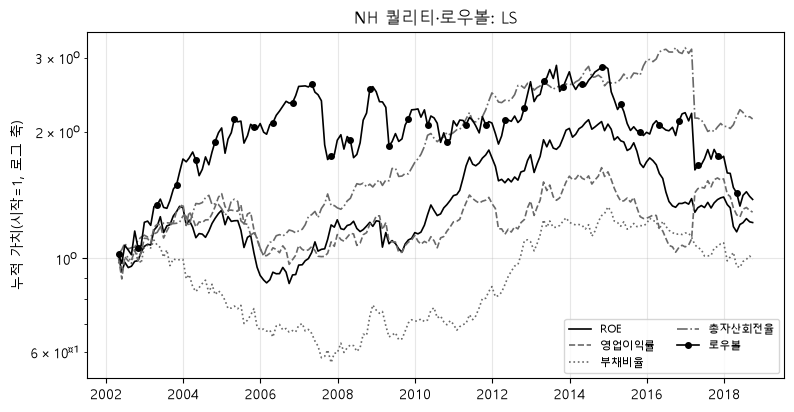

In [5]:
LS = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"]["Q5"] for n, o in 결과.items()})
평가.누적그림(LS, "NH 퀄리티·로우볼: LS");
평가.성과표(LS, F, list(LS))

## 6. 분위별 성과(지표별 Q1~Q5)

In [6]:
평가.성과표(pd.DataFrame({f"{n}_{g}": o["수익률"]["동일"][g] for n, o in 결과.items() for g in o["수익률"]["동일"]}), F)

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),초과평균 t(NW보정),CAPM α(월),CAPM t(OLS),CAPM t(NW),CAPM t(NW보정),FF3 α(월),FF3 t(OLS),FF3 t(NW),FF3 t(NW보정),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart t(NW보정),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
ROE_Q1,198.0000,9.2364,0.1514,0.2221,0.6158,-0.5349,0.8287,0.0114,2.5014,2.1892,2.1837,0.0074,3.2836,3.2520,3.2356,0.0054,2.9546,3.1805,3.1482,0.0044,2.4541,2.3738,2.3436,1.0636,0.5051,0.1719,0.1397,0.8665
ROE_Q2,198.0000,9.5085,0.1532,0.2065,0.6544,-0.4575,0.8426,0.0113,2.6580,2.3081,2.3023,0.0076,3.4887,3.2115,3.1953,0.0044,2.8004,2.8256,2.7969,0.0038,2.4130,2.3284,2.2988,0.9781,0.5362,0.2788,0.0866,0.8827
ROE_Q3,198.0000,10.0823,0.1569,0.2076,0.6667,-0.4844,0.7612,0.0116,2.7081,2.2971,2.2913,0.0080,3.2378,3.1807,3.1646,0.0036,2.3247,2.5700,2.5439,0.0034,2.1899,2.1574,2.1299,0.9367,0.6579,0.3960,0.0229,0.8838
ROE_Q4,198.0000,13.0656,0.1738,0.2332,0.6799,-0.5341,0.7874,0.0132,2.7618,2.3386,2.3327,0.0094,3.1893,2.9642,2.9492,0.0051,2.9116,3.0107,2.9801,0.0049,2.7972,2.8428,2.8067,1.0233,0.8163,0.3966,0.0182,0.8834
ROE_Q5,198.0000,5.3696,0.1188,0.2533,0.4548,-0.5959,0.4150,0.0096,1.8474,1.5995,1.5955,0.0057,1.6438,1.6180,1.6098,0.0044,1.8735,1.7037,1.6864,0.0052,2.1850,2.0471,2.0211,1.0586,0.8690,0.1622,-0.1069,0.8226
영업이익률_Q1,198.0000,8.7897,0.1483,0.2112,0.6207,-0.4819,0.6975,0.0109,2.5215,2.2011,2.1955,0.0074,2.9357,2.9375,2.9226,0.0050,2.2255,2.3359,2.3122,0.0042,1.8770,1.8482,1.8248,0.9512,0.4604,0.2017,0.1096,0.7674
영업이익률_Q2,198.0000,10.4249,0.1591,0.2199,0.6513,-0.5017,0.8448,0.0119,2.6457,2.3181,2.3123,0.0081,3.3962,3.3789,3.3618,0.0049,2.7503,2.8909,2.8616,0.0042,2.3632,2.3444,2.3146,1.0328,0.5712,0.2791,0.0976,0.8684
영업이익률_Q3,198.0000,11.8618,0.1674,0.2234,0.6755,-0.5094,0.8395,0.0126,2.7438,2.3504,2.3445,0.0087,3.3933,3.2472,3.2307,0.0042,2.6379,2.8352,2.8064,0.0038,2.3726,2.3443,2.3146,1.0244,0.6898,0.4008,0.0553,0.8940
영업이익률_Q4,198.0000,12.6389,0.1716,0.2258,0.6870,-0.5263,0.8274,0.0129,2.7908,2.3592,2.3532,0.0091,3.3591,3.1262,3.1103,0.0056,3.6041,3.8019,3.7633,0.0053,3.3691,3.5280,3.4832,1.0170,0.7728,0.3282,0.0434,0.9027
영업이익률_Q5,198.0000,4.4081,0.1077,0.2488,0.4183,-0.5801,0.3529,0.0087,1.6990,1.4656,1.4619,0.0048,1.4168,1.3704,1.3634,0.0032,1.4782,1.3493,1.3356,0.0042,1.9549,1.7611,1.7387,1.0365,0.8928,0.1974,-0.1419,0.8473


## 7. 리밸런싱 주기 비교 (그림 29·37)
총자산회전율(퀄리티)과 로우볼을 3·6·12개월 리밸런싱으로 다시 돌린다.

In [7]:
주기 = {}
for n in ["총자산회전율", "로우볼"]:
    for k in [3, 6, 12]:
        r = 포.실행({**기본, "지표": [지표들[n]], "리밸런싱": k})["수익률"]["동일"]
        주기[(n, k)] = {"Q1 누적": (1 + r["Q1"]).prod() - 1, "Q5 누적": (1 + r["Q5"]).prod() - 1, "LS 누적": (1 + r["Q1"] - r["Q5"]).prod() - 1}
pd.DataFrame(주기).T

Q1 누적  Q5 누적  LS 누적
총자산회전율 3  15.2473 5.2822 1.1452
       6  13.4362 4.4947 1.3079
       12 14.6987 3.3624 2.2213
로우볼    3  11.5465 3.2504 0.3813
       6  13.4119 1.9098 1.5564
       12 12.8464 1.1484 2.5981

## 8. 원문 vs 우리
원문은 숫자 표 없이 그림과 문장이라, 문장이 우리 결과에서도 성립하는지 참/거짓으로 본다.
'확인판(보통주만)' 칸은 로우볼을 우선주를 뺀 종목(코드 끝자리 0)으로만 다시 돌린 LS 판정이다. 원문 유니버스는 'KOSPI 상장종목'이라 우선주를 빼라는 말이 없어 본문은 우선주를 넣고, 새 데이터에 우선주 코드가 많아져(감사 2026-11-03 #3) 확인판을 나란히 둔다.
'확인판(자본>0만)' 칸은 ROE·부채비율을 자본이 0보다 큰 종목만으로 다시 계산한 것이다(자본이 음수면 ROE·부채비율 부호가 뒤집혀 Q1에 들어감, 11절). 두 칸이 다르면 그 판정은 음수 자본 처리에 따라 바뀌는 경계 결과다.

In [8]:
주기표 = pd.DataFrame(주기).T
판정 = lambda 누적: {"4개 퀄리티 지표 모두 2~4분위 누적이 가장 높음": all(누적.loc[n].idxmax() in ["Q2", "Q3", "Q4"] for n in list(지표들)[:4]),
       "4개 퀄리티 지표 모두 5분위 누적이 가장 낮음": all(누적.loc[n].idxmin() == "Q5" for n in list(지표들)[:4]),
       "로우볼 LS 누적이 양(+)": bool((1 + LS["로우볼"]).prod() - 1 > 0),
       "로우볼: 6·12개월 리밸런싱 LS 누적 > 3개월": bool(min(주기표.loc[("로우볼", 6), "LS 누적"], 주기표.loc[("로우볼", 12), "LS 누적"]) > 주기표.loc[("로우볼", 3), "LS 누적"])}
누적2 = 누적.copy()
for n in ["ROE", "부채비율"]:
    누적2.loc[n] = (1 + 포.실행({**기본, "지표": [(f"{n}_양자본", 지표들[n][1])]})["수익률"]["동일"]).prod() - 1
display((1 + 결과["ROE"]["수익률"]["동일"].loc["2008"]).prod().sub(1).rename("ROE 분위별 2008년 누적").to_frame())
display(pd.concat({"본문": 누적.loc[["ROE", "부채비율"]], "확인판(자본>0만)": 누적2.loc[["ROE", "부채비율"]]}))
판정표 = pd.DataFrame({"우리": 판정(누적), "확인판(자본>0만)": 판정(누적2)}).rename_axis("원문 주장")
보통 = 포.실행({**기본, "지표": [지표들["로우볼"]], "제외": ["보통주"] + 기본["제외"]})["수익률"]["동일"]
보통LS = (1 + 보통["Q1"] - 보통["Q5"]).prod() - 1
print(f"로우볼 LS 누적: 본문(우선주 포함) {(1 + LS['로우볼']).prod() - 1:.4f}, 확인판(보통주만) {보통LS:.4f}")
판정표["확인판(보통주만)"] = pd.Series({"로우볼 LS 누적이 양(+)": bool(보통LS > 0)})
판정표.to_csv(평가.결과폴더 / "03_원문판정.csv", encoding="utf-8-sig")  # 결과요약 노트북이 읽음
판정표

,ROE 분위별 2008년 누적
Q1,-0.4456
Q2,-0.3456
Q3,-0.3593
Q4,-0.4115
Q5,-0.4447


Q1     Q2      Q3      Q4     Q5
본문         ROE  9.2364 9.5085 10.0823 13.0656 5.3696
           부채비율 7.8173 9.3663 14.1442  8.9150 4.6788
확인판(자본>0만) ROE  7.9132 9.5224 10.0692 13.0757 5.4038
           부채비율 6.7845 9.2383 14.1167  8.9475 4.7318

로우볼 LS 누적: 본문(우선주 포함) 0.3813, 확인판(보통주만) 1.0621


,우리,확인판(자본>0만),확인판(보통주만)
원문 주장,,,
4개 퀄리티 지표 모두 2~4분위 누적이 가장 높음,False,False,NaN
4개 퀄리티 지표 모두 5분위 누적이 가장 낮음,True,True,NaN
로우볼 LS 누적이 양(+),True,True,True
로우볼: 6·12개월 리밸런싱 LS 누적 > 3개월,True,True,NaN


## 9. 확인판: 재무시점 180일, 무위험이자율
- **재무시점(연간 판)**: 본문은 분기 재무(발표일 없는 분기는 안 씀)라 150·180일 규칙이 없다. 예전 본문인 연간 재무에서 150일 대신 180일을 쓰면 LS 누적이 달라지는지 본다.
- **무위험이자율**: 본문은 콜금리(1일물 중개거래, E11.02.003.001). 1988년부터 빈 달 없이 값이 있는 금리는 이것과 무담보콜금리(1일물 은행간 직거래, E11.02.003.002) 둘이다. 확인판은 무담보콜, 그리고 2000년 이후 기간은 통안채 364일(E11.02.003.009, 1993-07부터 있음. NH 원문 기간이 모두 2000년 이후라 전체 기간에 쓰임). 무위험이자율은 포트폴리오를 바꾸지 않고 샤프·알파만 바꾼다(1분위로 본다).

In [9]:
연간 = {n: 포.실행({**기본, "재무주기": ("연간",), "지표": [m]}) for n, m in 지표들.items() if n != "로우볼"}
늦게 = {n: 포.실행({**기본, "재무주기": ("연간",), "지표": [m], "재무시점": ("발표일", 180)}) for n, m in 지표들.items() if n != "로우볼"}
lsof = lambda d: (1 + pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"]["Q5"] for n, o in d.items()})).prod() - 1
display(pd.DataFrame({"분기(본문)": (1 + LS.drop(columns="로우볼")).prod() - 1, "연간 150일": lsof(연간), "연간 180일": lsof(늦게)}).rename_axis("LS 누적"))
Q1x = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] for n, o in 결과.items()}).dropna(how="all")
금리 = {"콜(본문)": F, "무담보콜": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.002"}),
       "통안364(2000년 이후)": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.009"}).loc["2000":]}
pd.concat({k: 평가.성과표(Q1x.loc[f.index[0]:], f)[["샤프", "CAPM α(월)", "Carhart α(월)"]] for k, f in 금리.items()}, axis=1)

,분기(본문),연간 150일,연간 180일
LS 누적,,,
ROE,0.2173,-0.2324,-0.2385
영업이익률,0.2888,-0.0873,-0.0597
부채비율,-0.0031,0.1900,0.1580
총자산회전율,1.1452,1.4454,1.4351


콜(본문)                          무담보콜                        통안364(2000년 이후)                       
           샤프 CAPM α(월) Carhart α(월)     샤프 CAPM α(월) Carhart α(월)              샤프 CAPM α(월) Carhart α(월)
ROE    0.6158    0.0074       0.0044 0.6163    0.0074       0.0044          0.5975    0.0074       0.0044
영업이익률  0.6207    0.0074       0.0042 0.6213    0.0074       0.0042          0.6014    0.0073       0.0042
부채비율   0.6483    0.0069       0.0038 0.6489    0.0069       0.0038          0.6261    0.0069       0.0037
총자산회전율 0.7466    0.0099       0.0071 0.7471    0.0099       0.0071          0.7281    0.0099       0.0071
로우볼    0.9395    0.0089       0.0044 0.9403    0.0089       0.0044          0.9105    0.0088       0.0043

## 10. 확인: 리밸런싱마다 종목 수·빈칸으로 빠진 수

In [10]:
pd.concat({n: o["기록"] for n, o in 결과.items()}, axis=1).T

기준일               2002-03-29  2002-06-28  2002-09-30  2002-12-30  2003-03-31  2003-06-30  2003-09-30  2003-12-30  2004-03-31  2004-06-30  2004-09-30  2004-12-30  2005-03-31  2005-06-30  2005-09-30  2005-12-29  \
ROE    가격있음             1670        1674        1704        1714        1738        1722        1738        1746        1754        1731        1734        1749        1756        1725        1754        1787   
       시장                876         852         859         858         858         853         857         852         847         834         836         842         845         834         850         856   
       쓰지말것              876         852         859         858         858         853         857         852         846         833         835         841         844         833         849         855   
       거래정지              836         830         847         843         839         838         843         836         822         821         822         829         818         818         835         841   
       관리종목              720         736         752         761         771         773         782         783         772         770         775         790         802         801         820         826   
       빈칸:ROE            261         278         284         285         277         272         274         264         241         236         237         245         248         238         254         251   
       보유수:동일:Q1          92          92          94          96          99         101         102         104         107         107         108         109         111         113         114         115   
       보유수:동일:Q2          92          91          93          95          99         100         101         104         106         107         107         109         111         112         113         115   
       보유수:동일:Q3          91          92          94          95          98         100         102         103         106         106         108         109         110         113         113         115   
       보유수:동일:Q4          92          91          93          95          99         100         101         104         106         107         107         109         111         112         113         115   
       보유수:동일:Q5          92          92          94          95          99         100         102         104         106         107         108         109         111         113         113         115   
       빈칸으로 빠짐           261         278         284         285         277         272         274         264         241         236         237         245         248         238         254         251   
       편입:Q1              92          92          94          96          99         101         102         104         107         107         108         109         111         113         114         115   
       편입:Q2              92          91          93          95          99         100         101         104         106         107         107         109         111         112         113         115   
       편입:Q3              91          92          94          95          98         100         102         103         106         106         108         109         110         113         113         115   
       편입:Q4              92          91          93          95          99         100         101         104         106         107         107         109         111         112         113         115   
       편입:Q5              92          92          94          95          99         100         102         104         106         107         108         109         111         113         113         115   
       확인:업종빈칸             9           9          10           9          10          10          10          10           7           7           6           6           6           7

## 11. 차이 이유 후보
- **재무 주기**: 원문은 분기 재무도 발표 월말에 반영한다. 2026-11-04부터 본문도 분기 재무(추가 지시 F). 흐름 항목(순이익·영업이익·매출)을 4분기 합으로 할지는 원문에 없다(13절).
- **ROE·부채비율 정의**: 원문에 분모(기말/평균, 지배/전체) 정의가 없다. 우리는 ROE = 지배순이익/지배자본(기말), 부채비율 = 부채총계/자본총계.
- **변동성**: 원문은 12개월 일간 변동성. 원문에 최소 관측 기준이 없어 직전 12개월 내내 시장구분이 코스피·코스닥인 종목만 쓴다(코스닥에서 옮겨 온 종목도 코스닥 기간이 이어져 들어감, 코드 재사용 공백이 있으면 빠짐).
- **ROE 2008년 방어 효과(그림 26)**: 그림이라 참/거짓 숫자 기준이 없어 판정하지 않고, 8절의 'ROE 분위별 2008년 누적' 표로만 본다.
- **퀄리티 3·6개월 '차이 미미'(p.21)**: '미미'의 숫자 기준이 원문에 없어 참/거짓으로 판정하지 않고 7절 표(총자산회전율 3·6개월)로만 본다.
- **음수 분모**: ROE·부채비율은 공식 그대로라 자본이 음수인 종목은 ROE·부채비율 부호가 뒤집혀 좋은 쪽에 줄 설 수 있다(값은 고치지 않음).
- **벤치마크**: 시장지수는 코스피 가격지수(I.001, 배당 미포함)인데 포트폴리오는 배당 포함 수정주가(TR)다. 정보비율·CAPM α가 배당수익률만큼 높게 나온다(코스피 TR I.030은 X01에 있지만 원문 벤치마크가 아니라 쓰지 않음). KOSPI 행의 알파·t는 자기 자신 회귀라 뜻이 없다.

## 12. 원문과 다르게 한 것
| 항목 | 원문 | 우리 | 이유 |
|---|---|---|---|
| 재무 | 분기+연간, 발표 월의 월말 | 분기(3개월) 재무, 분기 보고서 발표일 다음 날부터. 흐름 = 최근 연속 4분기 합(원문에 없음), 잔액 = 최근 분기말. 발표일 없는 분기는 안 씀 | 2026-11-04 추가 지시 F로 연간 → 분기. 예전 연간 판(150·180일)은 9·13절 |
| 무위험이자율 | 원문에 없음 | 콜금리(E11.02.003.001) | 우리가 고름(9절 확인판) |
| 변동성 산출 기간 비교(12·36·60개월, 일·주·월 수익률) | 있음(그림 33·34). 본문 p.23은 '24개월, 36개월', 그림 33 범례는 '12·36·60개월'로 원문 안에서 다름 | 안 함(1년 일간만) | `지표.변동성` 하나만 만듦. 필요하면 함수 추가 |
| 시총 300위 이내 비교 | 있음(그림 27·35) | 안 함 | 같은 방식으로 `("시총상위", {"n": 300})`을 넣으면 됨 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | 리밸런싱일이 README_데이터의 '쓰지 말 것' 구간 (시작, 끝]에 드는 종목은 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 보유 중 걸린 칸은 TR 이상칸이면 그 구간 수정주가 수익률, 나머지는 빈칸(`포.쓰지말것칸`, 2026-11-04 고침: 전에는 다음 리밸런싱일까지 보고 뺌 = 미래 정보). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸의 앞날~그날(D-06·U3. 2026-11-04 같은 규칙으로 새 데이터에서 다시 만든 232칸, `_검증/새목록/`). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 가격·시장 일간 항목(S·CP 파일)에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름. 재무 일간은 끝나지 않은 회계연도가 빈칸이라 판정에서 뺌 | 통합_확인기록 F6(항목마다 끝 날짜가 다를 수 있음) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 재무 값 뽑기 | — | 달력기준 일간 재무에서 결산일(결산월 이력이 그 달인 달의 마지막 영업일) 값을 그 회계연도 값으로 씀(`읽기.연간재무`). 쓸 수 있는 날은 재무시점 규칙 | 일간 값은 발표 전부터 그 회계연도 값이 들어 있어 그대로 쓰면 미래 정보. 예전 연간 원본과 자산총계 79,657/79,837행 같음(`_검증/일간재무_대조_결과.txt`) |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |
| TR 이상칸 | — | 위 '쓰지 말 것' 칸 중 TR 이상칸이 이 노트북에 해당(배당 포함 가격을 씀) | README_데이터 D-06·U3 |


## 13. 원문 차이 진단 (2026-11-04)
값을 원문에 맞추려고 고르지 않는다. 원문은 숫자 표가 없고 그림·문장뿐이라(0단계 대조 30줄), 주장마다 판정 기준을 돌리기 전에 정했다.
- **주장 1(p.18, 그림 22~25)**: 지표마다 Q2~Q4 중 누적 최고가 Q1·Q5 중 누적 최고보다 크면 '같음'. 그 두 분위의 월수익률 차이 평균을 NW t로 검정해 p > 0.05이면 크기 방향과 관계없이 '경계'.
- **주장 2(p.18 '로우 퀄리티 현저히 낮음')**: 지표마다 Q5 누적이 다른 네 분위 중 최저보다 낮으면 '같음'. Q5와 그 최저 분위의 월 차이 평균 p > 0.05이면 '경계'('현저히'는 숫자 기준이 없어 판정에 안 넣음).
- **주장 4(p.26, 그림 37)**: 로우볼 LS 누적이 6·12개월 > 3개월. 3개월 대 6·12개월 LS 월 차이 평균 p > 0.05이면 '경계'. 같은 쪽 '6·12개월 비슷, 주기 영향 유의하지 않음'과도 맞는지 본다.
- **원인 바꾸기**: (가) 재무 주기 연간(예전 본문)·연간 180일·연간 발표 당일부터, (나) 분기 흐름 항목을 최근 분기 × 4로(원문에 없음), (다) 자본 > 0만(ROE·부채비율, 8절 확인판).

In [11]:
# (1) 주장 1·2를 지표마다, 판마다(본문 / 재무 180일 / 발표 당일부터 / 자본>0만)
def 지표판정(r):
    누 = (1 + r).prod() - 1
    중, 끝 = 누[["Q2", "Q3", "Q4"]].idxmax(), 누[["Q1", "Q5"]].idxmax()
    아래 = 누.drop("Q5").idxmin()
    p1, p2 = 평가.평균차이(r[중], r[끝])["p"], 평가.평균차이(r["Q5"], r[아래])["p"]
    판 = lambda ok, p: "경계" if p > 0.05 else ("같음" if ok else "다름")
    return {**{f"누적 {g}": 누[g] for g in 누.index}, "주장1: 중간 최고 대 끝 최고": f"{중} 대 {끝}", "주장1 p": p1, "주장1 판정": 판(누[중] > 누[끝], p1),
            "주장2: Q5 대 나머지 최저": f"Q5 대 {아래}", "주장2 p": p2, "주장2 판정": 판(누["Q5"] < 누[아래], p2)}
당일 = {n: 포.실행({**기본, "재무주기": ("연간",), "지표": [m], "재무시점": ("발표당일", 150)}) for n, m in 지표들.items() if n != "로우볼"}
곱4 = {n: 포.실행({**기본, "재무주기": ("분기", "최근분기x4"), "지표": [m]}) for n, m in 지표들.items() if n != "로우볼"}
양자본 = {n: 포.실행({**기본, "지표": [(f"{n}_양자본", 지표들[n][1])]}) for n in ["ROE", "부채비율"]}
판들 = {"본문(분기, 4분기 합)": 결과, "분기, 최근 분기 × 4": 곱4, "연간(예전 본문)": 연간, "연간 180일": 늦게, "연간 발표 당일부터": 당일, "자본>0만": 양자본}
지표별 = pd.concat({k: pd.DataFrame({n: 지표판정(o["수익률"]["동일"]) for n, o in res.items() if n != "로우볼"}).T for k, res in 판들.items()})
지표별

누적 Q1   누적 Q2   누적 Q3   누적 Q4  누적 Q5 주장1: 중간 최고 대 끝 최고  주장1 p 주장1 판정 주장2: Q5 대 나머지 최저  주장2 p 주장2 판정
본문(분기, 4분기 합) ROE     9.2364  9.5085 10.0823 13.0656 5.3696           Q4 대 Q1 0.4239     경계          Q5 대 Q1 0.5424     경계
              영업이익률   8.7897 10.4249 11.8618 12.6389 4.4081           Q4 대 Q1 0.4410     경계          Q5 대 Q1 0.4884     경계
              부채비율    7.8173  9.3663 14.1442  8.9150 4.6788           Q3 대 Q1 0.0441     같음          Q5 대 Q1 0.7906     경계
              총자산회전율 15.2473  9.6721  9.5107  8.9857 5.2822           Q2 대 Q1 0.0600     경계          Q5 대 Q4 0.4055     경계
분기, 최근 분기 × 4 ROE    17.3373 11.6806  9.4144  7.7653 2.5889           Q2 대 Q1 0.1901     경계          Q5 대 Q4 0.0699     경계
              영업이익률  12.2185 11.4380 12.5247 10.0277 2.0619           Q3 대 Q1 0.9280     경계          Q5 대 Q4 0.0003     같음
              부채비율    7.8173  9.3663 14.1442  8.9150 4.6788           Q3 대 Q1 0.0441     같음          Q5 대 Q1 0.7906     경계
              총자산회전율 16.2275 11.3810  7.9436  7.0777 4.0932           Q2 대 Q1 0.1523     경계          Q5 대 Q4 0.3853     경계
연간(예전 본문)     ROE     4.7746 10.0953  9.7995 11.0293 4.7197           Q4 대 Q1 0.0434     같음          Q5 대 Q1 0.8227     경계
              영업이익률   6.9804  5.4689 12.6758 11.2641 4.4652           Q3 대 Q1 0.1747     경계          Q5 대 Q2 0.9532     경계
              부채비율    7.8362  8.9025 12.0999  8.9845 3.3054           Q3 대 Q1 0.2925     경계          Q5 대 Q1 0.5568     경계
              총자산회전율 11.9836  9.7598  8.7104  6.7617 3.9003           Q2 대 Q1 0.4599     경계          Q5 대 Q4 0.2843     경계
연간 180일       ROE     4.8117  9.8602  9.8856 11.0218 4.8053           Q4 대 Q1 0.0451     같음          Q5 대 Q1 0.8102     경계
              영업이익률   7.0063  5.5489 12.4215 11.7208 4.3210           Q3 대 Q1 0.1872     경계          Q5 대 Q2 0.9017     경계
              부채비율    7.6640  9.0435 11.8487  9.1790 3.3607           Q3 대 Q1 0.2914     경계          Q5 대 Q1 0.5839     경계
              총자산회전율 12.0605  9.7340  8.5087  6.8736 3.9494           Q2 대 Q1 0.4349     경계          Q5 대 Q4 0.2806     경계
연간 발표 당일부터    ROE     4.5184 10.2653 10.0331 10.6613 4.9496           Q4 대 Q5 0.1674     경계          Q5 대 Q1 0.7043     경계
              영업이익률   6.6322  5.7328 12.8257 11.4817 4.3528           Q3 대 Q1 0.1525     경계          Q5 대 Q2 0.8720     경계
              부채비율    8.2068  8.8429 12.0768  8.8023 3.2591           Q3 대 Q1 0.3338     경계          Q5 대 Q1 0.4892     경계
              총자산회전율 11.9526  9.8020  8.6365  6.5177 4.0993           Q2 대 Q1 0.4774     경계          Q5 대 Q4 0.3739     경계
자본>0만         ROE     7.9132  9.5224 10.0692 13.0757 5.4038           Q4 대 Q1 0.2300     경계          Q5 대 Q1 0.7416     경계
              부채비율    6.7845  9.2383 14.1167  8.9475 4.7318           Q3 대 Q1 0.0050     같음          Q5 대 Q1 0.9819     경계

In [12]:
# (2) 주장 4: 로우볼 리밸런싱 3 대 6·12개월
볼LS = {k: (lambda r: r["Q1"] - r["Q5"])(포.실행({**기본, "지표": [지표들["로우볼"]], "리밸런싱": k})["수익률"]["동일"]) for k in (3, 6, 12)}
주장4 = pd.DataFrame({f"{k}개월 대 3개월": 평가.평균차이(볼LS[k], 볼LS[3]) for k in (6, 12)} | {"12개월 대 6개월": 평가.평균차이(볼LS[12], 볼LS[6])}).T
주장4["누적(앞)"] = [(1 + 볼LS[k]).prod() - 1 for k in (6, 12, 12)]
주장4["누적(뒤)"] = [(1 + 볼LS[k]).prod() - 1 for k in (3, 3, 6)]
주장4["판정"] = np.where(주장4["p"] > 0.05, "경계", np.where(주장4["누적(앞)"] > 주장4["누적(뒤)"], "앞이 큼", "뒤가 큼"))
주장4

,월수,평균 차이(월),t(NW),p,누적(앞),누적(뒤),판정
6개월 대 3개월,198.0000,0.0029,2.3351,0.0195,1.5564,0.3813,앞이 큼
12개월 대 3개월,198.0000,0.0045,2.3040,0.0212,2.5981,0.3813,앞이 큼
12개월 대 6개월,198.0000,0.0016,1.2253,0.2205,2.5981,1.5564,경계


### 원문 차이 진단 요약
| 원인 | 근거 | 바꾼 뒤 숫자 | 원문 | 남은 차이 |
|---|---|---|---|---|
| 재무 주기 연간(예전 본문) | 원문 p.18 '분기/연간' → 본문은 분기로 고침 | (1) 표 '연간(예전 본문)'·'연간 180일'·'연간 발표 당일부터' 줄 | 주장 1·2(그림 22~25) | (1) 표 판정 칸 |
| 분기 흐름 항목 정의 | 원문에 없음 | (1) 표 '분기, 최근 분기 × 4' 줄 | 주장 1·2 | 같은 칸 |
| 음수 자본 | 원문에 정의 없음(이름만, p.18) | (1) 표 '자본>0만' 줄(ROE·부채비율) | 주장 1·2 | 같은 칸 |
| 근소한 분위 차이(ROE Q1 대 Q5 등) | — | (1) 표 p | — | p > 0.05면 '경계' |
| 로우볼 주기 | 원문 p.26 그림 37 | (2) 표 | 6·12개월 > 3개월, 6·12개월 비슷 | (2) 표 판정 |

숫자는 위 코드 출력이 정본이다. 본문은 원문 문장대로 분기 재무로 바꿨다(2026-11-04 추가 지시 F). 4분기 합·자본 > 0은 원문에 없는 선택이라 진단 판으로만 둔다.

## 14. 요약표용 저장
지표별 Q1과 LS의 월수익률을 `결과_월수익률/`에 남긴다.

In [13]:
S = pd.DataFrame({(f"NH퀄리티로우볼 {n} Q1", "동일"): o["수익률"]["동일"]["Q1"] for n, o in 결과.items()} | {(f"NH퀄리티로우볼 {n} LS", "동일"): LS[n] for n in LS})
평가.저장(S, F, "03_NH퀄리티로우볼", [k for k in S if k[0].endswith(" LS")])
list(S)

[('NH퀄리티로우볼 ROE Q1', '동일'),
 ('NH퀄리티로우볼 영업이익률 Q1', '동일'),
 ('NH퀄리티로우볼 부채비율 Q1', '동일'),
 ('NH퀄리티로우볼 총자산회전율 Q1', '동일'),
 ('NH퀄리티로우볼 로우볼 Q1', '동일'),
 ('NH퀄리티로우볼 ROE LS', '동일'),
 ('NH퀄리티로우볼 영업이익률 LS', '동일'),
 ('NH퀄리티로우볼 부채비율 LS', '동일'),
 ('NH퀄리티로우볼 총자산회전율 LS', '동일'),
 ('NH퀄리티로우볼 로우볼 LS', '동일')]